# Experimento de ML (utilizando PCA)
___

### Importações de bibliotecas

In [4]:
# Manipulação de dados:
import pandas as pd
import numpy as np

# Pré-processamento:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Modelos:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

# Avaliação dos modelos:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Visualização gráfica:
import matplotlib.pyplot as plt

In [5]:
# Importando o dataset:
df = pd.read_csv('../data/raw/dataset.csv')
df

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113995,113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.2350,...,-16.393,1,0.0422,0.6400,0.928000,0.0863,0.0339,125.995,5,world-music
113996,113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.1170,...,-18.318,0,0.0401,0.9940,0.976000,0.1050,0.0350,85.239,4,world-music
113997,113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.3290,...,-10.895,0,0.0420,0.8670,0.000000,0.0839,0.7430,132.378,4,world-music
113998,113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.5060,...,-10.889,1,0.0297,0.3810,0.000000,0.2700,0.4130,135.960,4,world-music


### Pré-processamento do dataset
___

In [6]:
print(f'Numero de amostras antes da amputação/tratamento:   {df.shape[0]}')

df_base = df.loc[:, ~df.columns.str.contains('^Unnamed')]

# Guarda metadados alinhados para inspeção posterior das recomendações
cols_meta = [c for c in ["track_id", "artists", "album_name", "track_name", "track_genre"] if c in df_base.columns]
df_meta = df_base[cols_meta].copy()

# 4. Filtra apenas colunas numéricas para modelagem/similaridade
colunas_para_remover = ["track_id", "artists", "album_name", "track_name", "track_genre", "explicit"]
df_clean = df_base.drop(columns=[c for c in colunas_para_remover if c in df_base.columns], errors="ignore")
df_clean = df_clean.select_dtypes(include=["number"])

# 5. Remove duplicatas exatas no espaço de features numéricas mantendo alinhamento com df_meta
mask_keep = (~df_clean.isna().any(axis=1)) & (~df_clean.duplicated())
df_clean = df_clean.loc[mask_keep].reset_index(drop=True)
df_meta = df_meta.loc[mask_keep].reset_index(drop=True)

print(f"Numero de amostras após amputação/tratamento:       {df_clean.shape[0]}")
print(f"Numero de features após amputação/tratamento:       {df_clean.shape[1]}")

Numero de amostras antes da amputação/tratamento:   114000
Numero de amostras após amputação/tratamento:       86705
Numero de features após amputação/tratamento:       14


In [7]:
# Selecionando as features numéricas para ML:
features_numericas = [
    'popularity', 'duration_ms', 'danceability', 'energy', 'key', 
    'loudness', 'speechiness', 'acousticness', 
    'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'mode'
]
X = df_clean[[col for col in features_numericas if col in df_clean.columns]].select_dtypes(include=[np.number])

In [8]:
# Normalização do dataset (especialmente para trabalhar com PCA):
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### Redução de dimensionalidade com PCA:
___

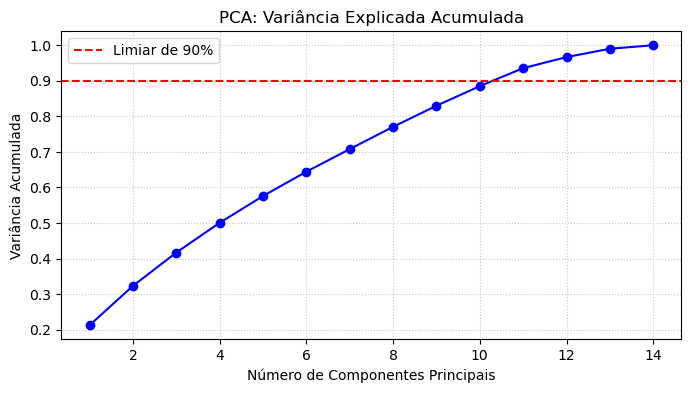

-> Componentes selecionados pelo critério de 90%: 11


In [9]:
# Rodando PCA completo para avaliar a variância
pca_full = PCA()
pca_full.fit(X_scaled)
variancia_acumulada = np.cumsum(pca_full.explained_variance_ratio_)

# Gráfico da Variância Explicada Acumulada
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(variancia_acumulada) + 1), variancia_acumulada, marker='o', linestyle='-', color='b')
plt.axhline(y=0.90, color='r', linestyle='--', label='Limiar de 90%')
plt.title('PCA: Variância Explicada Acumulada')
plt.xlabel('Número de Componentes Principais')
plt.ylabel('Variância Acumulada')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.show()

# Escolhendo automaticamente o número de componentes para atingir 90% da variância
n_comp_escolhido = np.argmax(variancia_acumulada >= 0.90) + 1
print(f"-> Componentes selecionados pelo critério de 90%: {n_comp_escolhido}")

# Aplicando o PCA definitivo com o número escolhido
pca_definitivo = PCA(n_components=n_comp_escolhido, random_state=42)
X_pca = pca_definitivo.fit_transform(X_scaled)

### Imeplementação e averiguação do K-Means:
___
Além de implementar, busca o melhor valor _k_ de número de clusters:

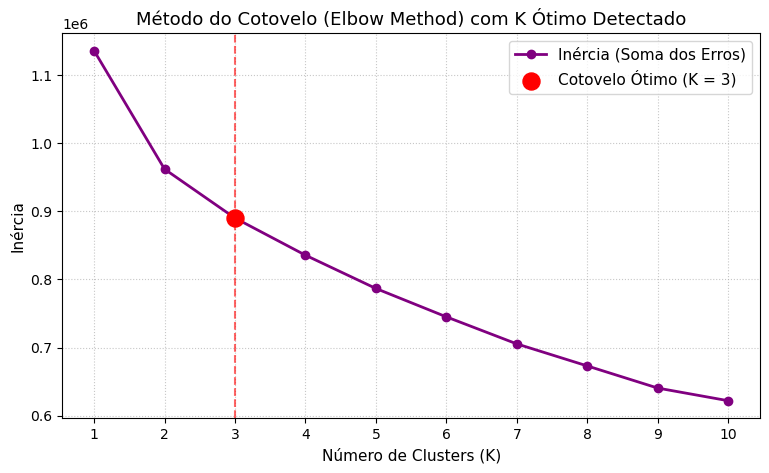

-> O número adequado de clusters sugerido matematicamente é: K = 3


In [10]:
inercia = []
k_valores = list(range(1, min(11, len(X_pca) + 1)))  # Testa K de 1 até 10

for k in k_valores:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_pca)
    inercia.append(kmeans.inertia_)

# Detecta valores/distâncias para o gráfico de cotovelo
x1, y1 = float(k_valores[0]), float(inercia[0])
x2, y2 = float(k_valores[-1]), float(inercia[-1])

denominador = np.hypot(y2 - y1, x2 - x1)  # Equivalente a sqrt((y2 - y1)**2 + (x2 - x1)**2)

distancias = []
for k, inertia_val in zip(k_valores, inercia):
    x0, y0 = float(k), float(inertia_val)
    numerador = abs((y2 - y1) * x0 - (x2 - x1) * y0 + x2 * y1 - y2 * x1)
    distancia = numerador / denominador if denominador > 0 else 0.0
    distancias.append(distancia)

# O K ótimo é o que possui a maior distância perpendicular à reta
melhor_k_idx = int(np.argmax(distancias))
melhor_k = k_valores[melhor_k_idx]

# PLOTAGEM DO GRÁFICO
plt.figure(figsize=(9, 5))
plt.plot(k_valores, inercia, marker='o', linestyle='-', color='purple', linewidth=2, label='Inércia (Soma dos Erros)')

plt.scatter(melhor_k, inercia[melhor_k_idx], color='red', s=150, zorder=5, label=f'Cotovelo Ótimo (K = {melhor_k})')
plt.axvline(x=melhor_k, color='red', linestyle='--', alpha=0.6)

plt.title('Método do Cotovelo (Elbow Method) com K Ótimo Detectado', fontsize=13)
plt.xlabel('Número de Clusters (K)', fontsize=11)
plt.ylabel('Inércia', fontsize=11)
plt.xticks(k_valores)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=11)
plt.show()

print(f"-> O número adequado de clusters sugerido matematicamente é: K = {melhor_k}")

In [11]:
# Treina o K-Means definitivo no espaço PCA
k_final = melhor_k 
kmeans_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
labels_kmeans = kmeans_final.fit_predict(X_pca)

# Avaliação do desempenho do K-Means
n_amostra = min(15000, len(X_pca))
sil_score = silhouette_score(X_pca, labels_kmeans, random_state=42)
db_score = davies_bouldin_score(X_pca, labels_kmeans)
ch_score = calinski_harabasz_score(X_pca, labels_kmeans)

print(f'-' * 50)
print(f"Avaliação do K-Means (K = {k_final}) | PCA ({X_pca.shape[1]} Dimensões) ")
print(f'-' * 50)
print(f"Coeficiente de Silhueta:  {sil_score:.4f}")
print(f"Índice de Davies-Bouldin:        {db_score:.4f}")
print(f"Índice de Calinski-Harabasz:     {ch_score:.2f}")
print(f'-' * 50)

--------------------------------------------------
Avaliação do K-Means (K = 3) | PCA (11 Dimensões) 
--------------------------------------------------
Coeficiente de Silhueta:  0.1104
Índice de Davies-Bouldin:        2.4105
Índice de Calinski-Harabasz:     11960.63
--------------------------------------------------


### Implementação e averiguação do GMM
___


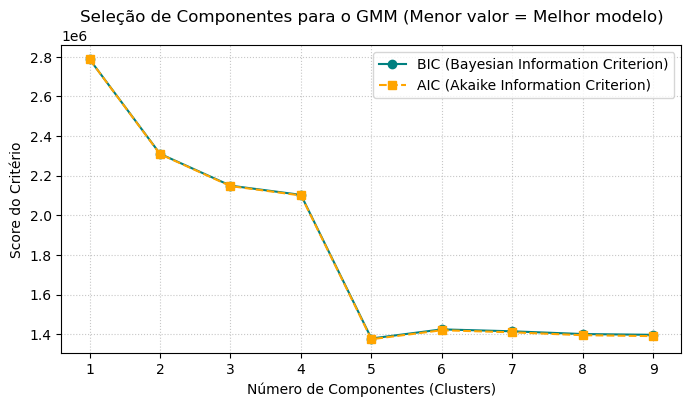

-> Número ideal de componentes sugerido pelo BIC para o GMM: 5


In [12]:
n_components_range = range(1, min(10, len(X_pca) + 1))
bic_scores = []
aic_scores = []

for n in n_components_range:
    # O GMM utiliza covariância completa por padrão, mas 'full', 'diag' ou 'spherical' podem ser testados
    gmm = GaussianMixture(n_components=n, covariance_type='full', random_state=42)
    gmm.fit(X_pca)
    bic_scores.append(gmm.bic(X_pca))
    aic_scores.append(gmm.aic(X_pca))

# Plotando os critérios BIC e AIC para escolha do número de componentes do GMM
plt.figure(figsize=(8, 4))
plt.plot(n_components_range, bic_scores, marker='o', linestyle='-', color='teal', label='BIC (Bayesian Information Criterion)')
plt.plot(n_components_range, aic_scores, marker='s', linestyle='--', color='orange', label='AIC (Akaike Information Criterion)')
plt.title('Seleção de Componentes para o GMM (Menor valor = Melhor modelo)')
plt.xlabel('Número de Componentes (Clusters)')
plt.ylabel('Score do Critério')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.show()

# Encontrando o número ideal de componentes (onde o BIC é mínimo)
melhor_k_gmm = n_components_range[np.argmin(bic_scores)]
print(f"-> Número ideal de componentes sugerido pelo BIC para o GMM: {melhor_k_gmm}")

In [13]:
# 1. Treina o GMM definitivo com o melhor K encontrado
gmm_definitivo = GaussianMixture(
    n_components=melhor_k_gmm,
    covariance_type='full',
    random_state=42
)
labels_gmm = gmm_definitivo.fit_predict(X_pca)
probs_gmm = gmm_definitivo.predict_proba(X_pca)  # Probabilidades de pertinência (soft clustering)

# 2. Métricas próprias do modelo probabilístico
bic_val = gmm_definitivo.bic(X_pca)
aic_val = gmm_definitivo.aic(X_pca)
log_likelihood_medio = gmm_definitivo.score(X_pca)  # Média do log-verossimilhança por amostra

print(f'-' * 50)
print(f"Avaliação do K-Means (K = {k_final}) | PCA ({X_pca.shape[1]} Dimensões) ")
print(f'-' * 50)
print(f"Coeficiente de Silhueta:  {sil_score:.4f}")
print(f"Índice de Davies-Bouldin:        {db_score:.4f}")
print(f"Índice de Calinski-Harabasz:     {ch_score:.2f}")
print(f'-' * 50)

# 3. Métricas intrínsecas de clusterização (comparáveis ao K-Means e DBSCAN)
n_clusters_gmm = len(np.unique(labels_gmm))
print('-' * 50)
print(f"Avaliação do GMM (K = {melhor_k_gmm}) | PCA ({X_pca.shape[1]} Dimensões)")
print('-' * 50)
print(f"BIC:                          {bic_val:.2f}")
print(f"AIC:                          {aic_val:.2f}")
print(f"Log-Likelihood médio/amostra: {log_likelihood_medio:.4f}")
print('-' * 50)
if n_clusters_gmm >= 2:
    n_amostra_gmm = min(10000, len(X_pca))
    sil_gmm = silhouette_score(X_pca, labels_gmm, random_state=42)
    db_gmm = davies_bouldin_score(X_pca, labels_gmm)
    ch_gmm = calinski_harabasz_score(X_pca, labels_gmm)

    print(f"Coeficiente de Silhueta: {sil_gmm:.4f}")
    print(f"Índice de Davies-Bouldin:      {db_gmm:.4f}")
    print(f"Índice de Calinski-Harabasz:  {ch_gmm:.2f}")
else:
    print("Menos de 2 clusters distintos atribuídos pelo argmax; métricas geométricas omitidas.")

print('-' * 50)

# Distribuição das faixas pelo cluster mais provável
valores, contagens = np.unique(labels_gmm, return_counts=True)
for c, qtd in zip(valores, contagens):
    print(f"  - Componente/Cluster {c}: {qtd} músicas ({qtd / len(labels_gmm) * 100:.1f}%)")

# Incerteza média de atribuição (1 - maior probabilidade por música)
incerteza_media = np.mean(1.0 - np.max(probs_gmm, axis=1))
print(f"Incerteza média de pertinência (soft clustering): {incerteza_media:.4f}")

--------------------------------------------------
Avaliação do K-Means (K = 3) | PCA (11 Dimensões) 
--------------------------------------------------
Coeficiente de Silhueta:  0.1104
Índice de Davies-Bouldin:        2.4105
Índice de Calinski-Harabasz:     11960.63
--------------------------------------------------
--------------------------------------------------
Avaliação do GMM (K = 5) | PCA (11 Dimensões)
--------------------------------------------------
BIC:                          1378280.53
AIC:                          1374635.49
Log-Likelihood médio/amostra: -7.9226
--------------------------------------------------
Coeficiente de Silhueta: 0.0899
Índice de Davies-Bouldin:      2.5351
Índice de Calinski-Harabasz:  5518.69
--------------------------------------------------
  - Componente/Cluster 0: 27858 músicas (32.1%)
  - Componente/Cluster 1: 35618 músicas (41.1%)
  - Componente/Cluster 2: 3615 músicas (4.2%)
  - Componente/Cluster 3: 7578 músicas (8.7%)
  - Componente/

### Criação do dataset de recomendação
___
O dataset final é dividido em parte numérica para cálculos e não-numérica para descrição dos dados.

In [15]:
labels_map = {
    "cluster_pca_kmeans": labels_kmeans,
    "cluster_pca_gmm": labels_gmm,
}

n_samples = X.shape[0]
assert df_meta.shape[0] == n_samples, (
    f"df_meta ({df_meta.shape[0]}) e X ({n_samples}) têm tamanhos diferentes!"
)

for col_name, arr in labels_map.items():
    arr_np = np.asarray(arr)
    assert arr_np.shape[0] == n_samples, (
        f"Tamanho incompatível em {col_name}: esperado {n_samples}, recebido {arr_np.shape[0]}"
    )

# 2. DataFrame numérico (features numéricas + rótulos de cluster)
df_final_numerico = pd.concat(
    [
        X.reset_index(drop=True),
        pd.DataFrame({k: np.asarray(v) for k, v in labels_map.items()}),
    ],
    axis=1,
)

# Garante que não sobrou nenhuma coluna não numérica em df_numerico
df_final_numerico = df_final_numerico.select_dtypes(include=[np.number])

# 3. DataFrame não numérico / metadados alinhado pelo mesmo índice
df_final_descritivo = (
    df_meta.select_dtypes(exclude=[np.number])
    .reset_index(drop=True)
    if not df_meta.select_dtypes(exclude=[np.number]).empty
    else df_meta.reset_index(drop=True)
)

df_final_numerico.to_csv('../data/pca/df_pca_numerico.csv', index=False)
df_final_descritivo.to_csv('../data/pca/df_pca_descritivo.csv', index=False)